Test what happens if we close the loop with open-loop predictions.

In [47]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel, SquareCoarseExtendedModel
from Components.Controllers import LTI_LQRc_RHG, LTI_LQRc_RHG_mixed_state
from Components.Solver import fbrs

In [48]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [49]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [50]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = SquareCoarseExtendedModel(parameter_file, boundary_condition="Constant Head")
# Initialize Controller
controller = LTI_LQRc_RHG_mixed_state(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    [A.toarray() for A in model.A_s_v], [B.toarray() for B in model.B_s_v], [C.toarray() for C in model.C_s_v],
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    None, None,
    Q_v = [G.toarray() for G in model.Gamma_v_tilde], R_v = None, M_v = None, L_v = [Xi for Xi in model.Xi_v],
    solver='fbrs'
)
# Initialize receding horizon
receding_horizon = RecedingHorizon(system, model, controller, parameter_file)

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_array is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/scipy/sparse/_index.py:201: SparseEfficiencyWarning: Changing the sparsity structure of a csr_array is expensive. lil and dok are more efficient.
  self._set_arrayXarray_sparse(i, j, x)


In [51]:
def step(record_results: bool=False):
    inputs, x_pred = controller.step(model.get_initial_state())
    pumping_rates = model.translate_input(inputs[[0], :].T)
    if record_results:
        receding_horizon._record_data(pumping_rates, x_pred)
    system.apply_command(pumping_rates)
    model.state = x_pred[:,[1]]
    return x_pred[:,[1]]


def run(time_period: int, display_results: bool=False) -> np.ndarray:
    x = model.translate_state(system.get_state()[0,:,:])
    for t in trange(time_period, desc="Simulation progress"):
        step(record_results=display_results)
    if display_results:
        receding_horizon._display_results()
        receding_horizon._store_data()
    return

Simulation progress: 100%|██████████| 200/200 [00:30<00:00,  6.62it/s]
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:113: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_h.show()
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:114: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_q.show()
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:115: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_p.show()


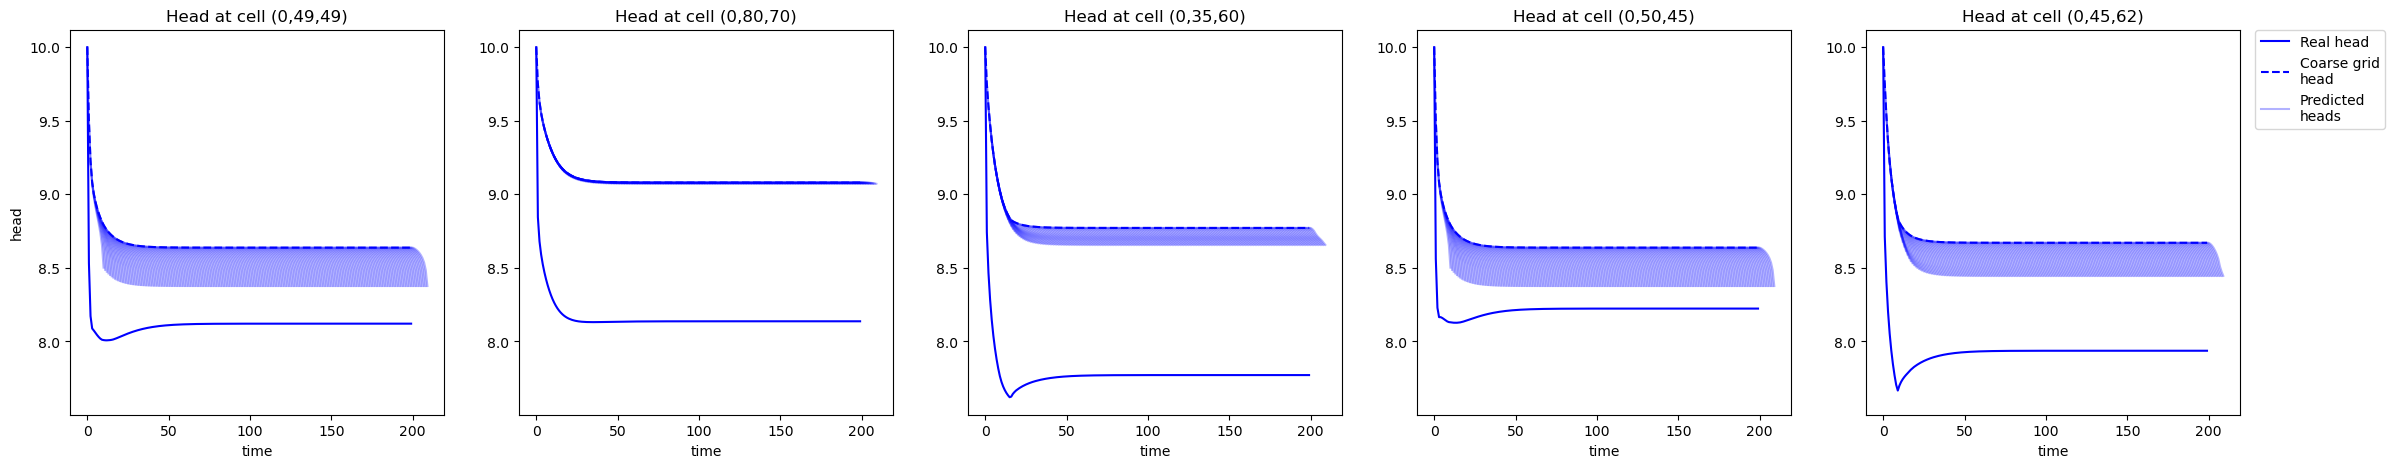

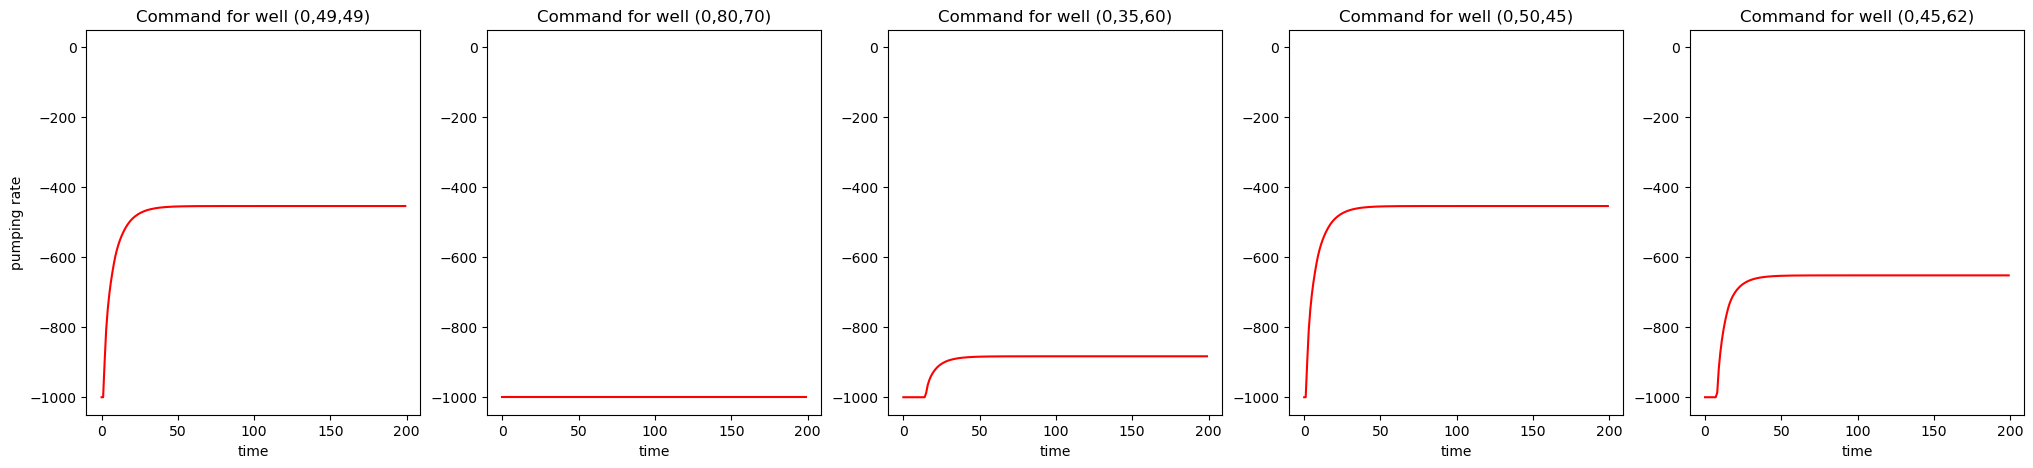

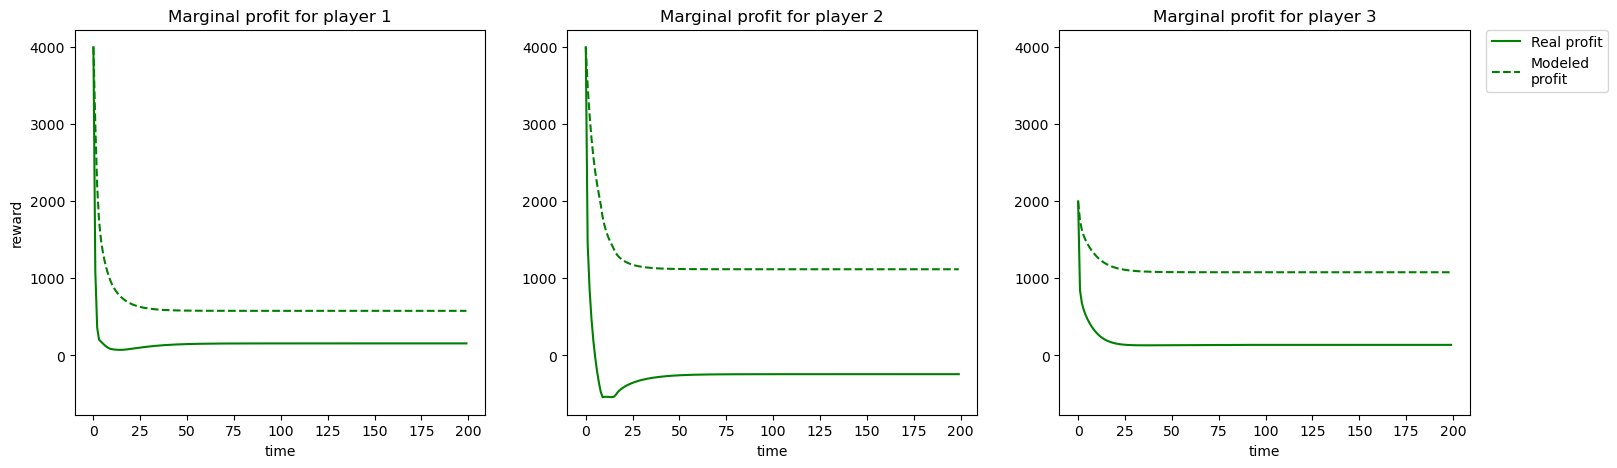

In [52]:
run(time_period=200, display_results=True)

# Compare to equilibrium

In [58]:
data = np.load("run_data/run_20250520-130233/result_data.npz")

In [70]:
h_eq = np.array([8.73300538, 9.10011198, 8.86300069, 8.73300538, 8.77295862])
u_eq = np.array([ -422.59353395, -1000.        , -817.65051264,   -422.59353395, -584.66665444])

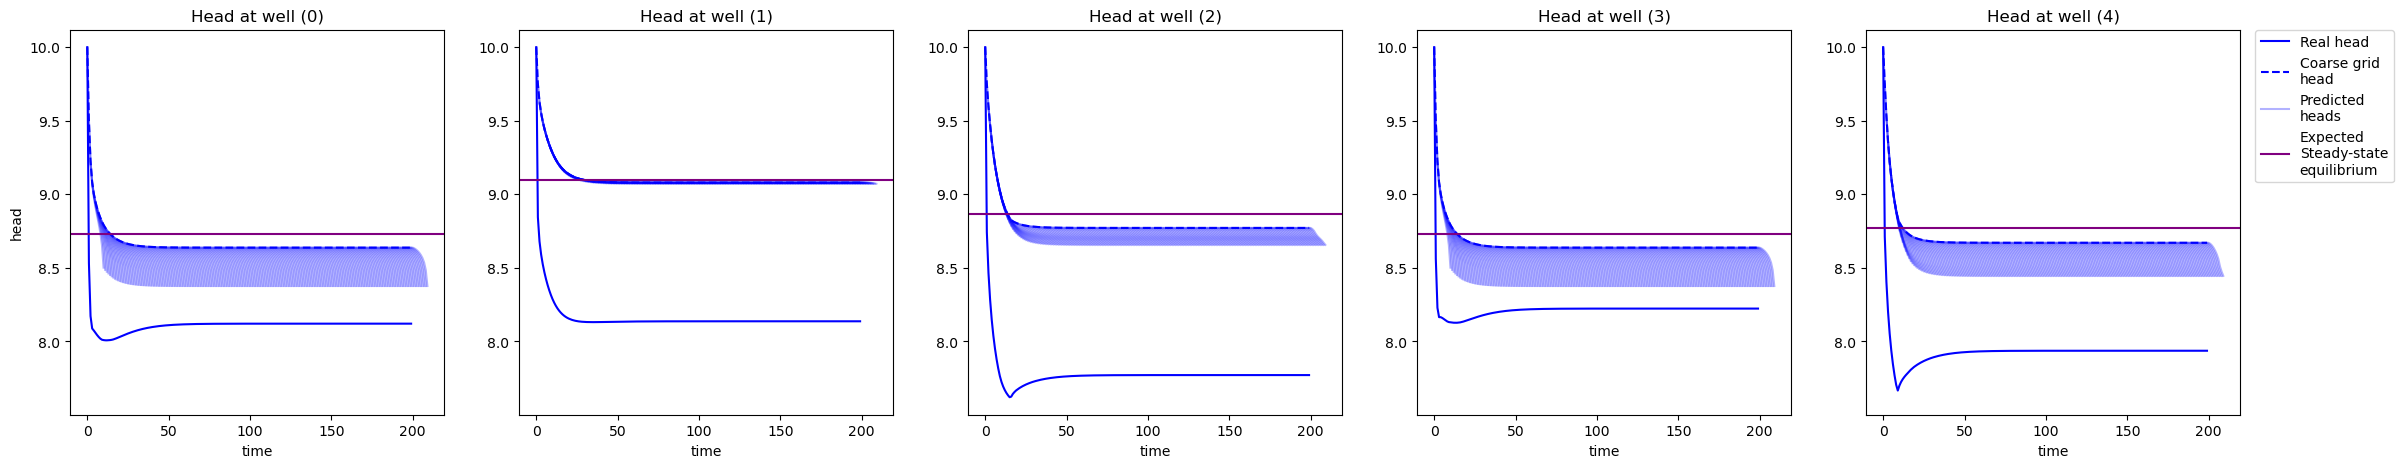

In [59]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data['avg_h_wells'][ii, :], "b--", label="Coarse grid\nhead")
    # Display predicted evolution
    dt = np.linspace(0,10, 11)
    for t0, h_pred in enumerate(np.rollaxis(data['pred_avg_h_wells'], 2)):
        t = t0 + dt
        ax_h.plot(t, h_pred[ii, :], "b-", alpha=0.3,
                    label="Predicted\nheads" if t0==0 else None)
    ax_h.axhline(h_eq[ii], c="purple", label="Expected\nSteady-state\nequilibrium")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

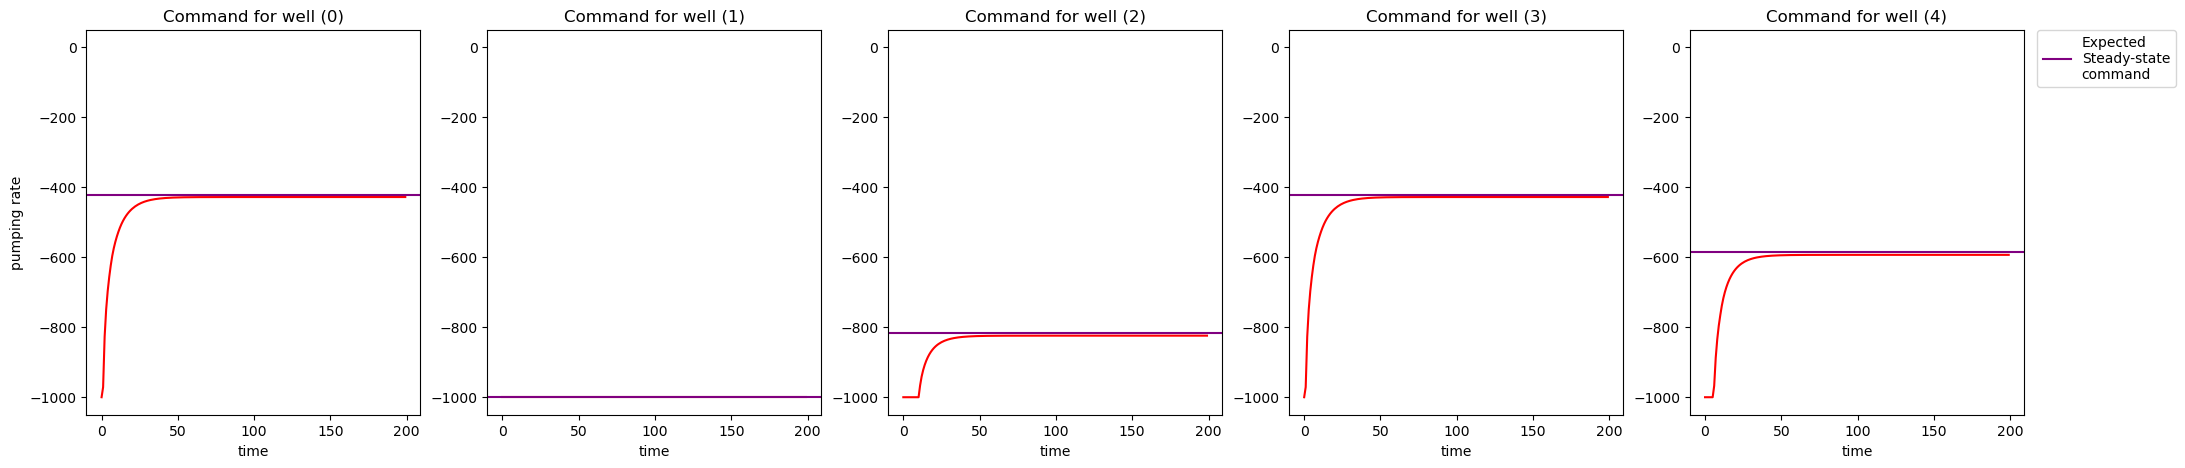

In [71]:
fig_q = plt.figure(figsize=(25,5))
ax_q = None
for ii in range(5):
    ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
    ttl = f"Command for well ({ii})"
    ax_q.set_title(ttl)
    ax_q.set_xlabel("time")
    if ii == 0:
        ax_q.set_ylabel("pumping rate")
    ax_q.plot(data['q_rates'][ii, :], "r-")
    ax_q.axhline(u_eq[ii], c="purple", label="Expected\nSteady-state\ncommand")
    ax_q.set_ylim([-1050, 50])
ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# Longer prediction horizon

To reduce impact of Turnpike effect.

In [62]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = SquareCoarseExtendedModel(parameter_file, boundary_condition="Constant Head")
# Initialize Controller
controller = LTI_LQRc_RHG_mixed_state(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    [A.toarray() for A in model.A_s_v], [B.toarray() for B in model.B_s_v], [C.toarray() for C in model.C_s_v],
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    None, None,
    Q_v = [G.toarray() for G in model.Gamma_v_tilde], R_v = None, M_v = None, L_v = [Xi for Xi in model.Xi_v],
    solver='fbrs'
)
# Initialize receding horizon
receding_horizon = RecedingHorizon(system, model, controller, parameter_file)

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_array is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/scipy/sparse/_index.py:201: SparseEfficiencyWarning: Changing the sparsity structure of a csr_array is expensive. lil and dok are more efficient.
  self._set_arrayXarray_sparse(i, j, x)


Simulation progress: 100%|██████████| 200/200 [01:18<00:00,  2.54it/s]
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:113: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_h.show()
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:114: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_q.show()
/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/RecedingHorizon.py:115: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_p.show()


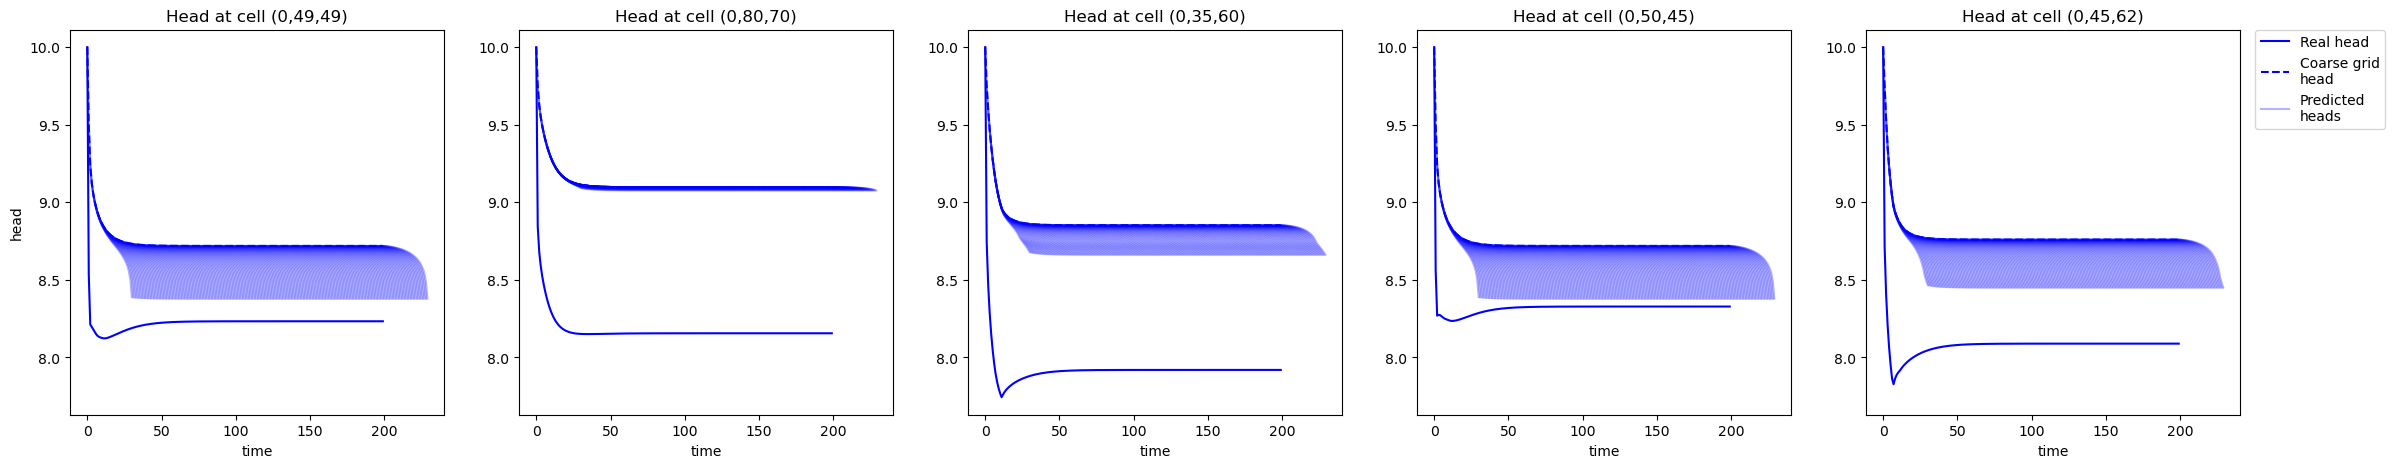

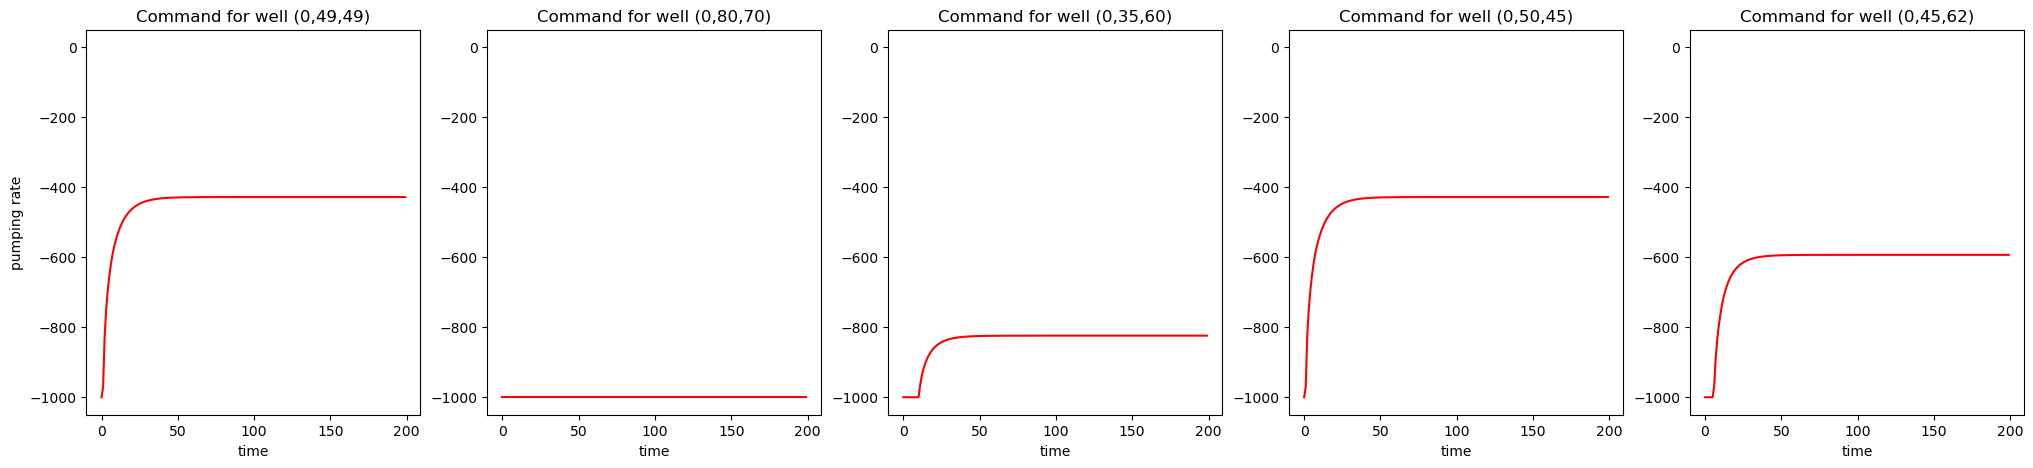

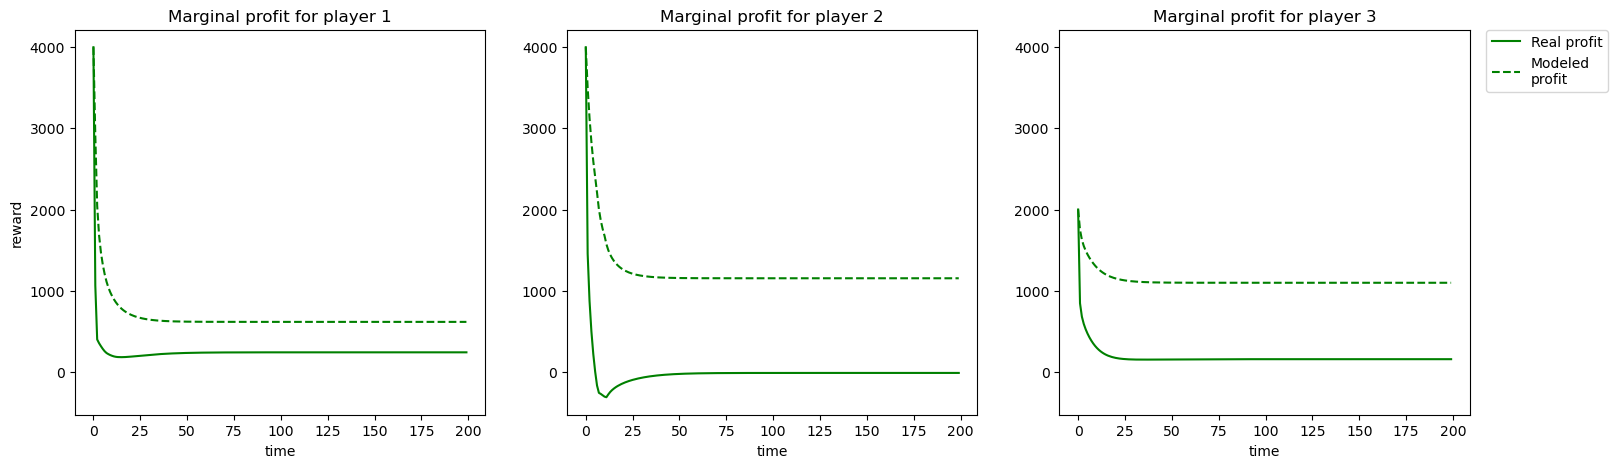

In [63]:
run(time_period=200, display_results=True)

In [81]:
data = np.load("run_data/run_20250520-142320/result_data.npz")

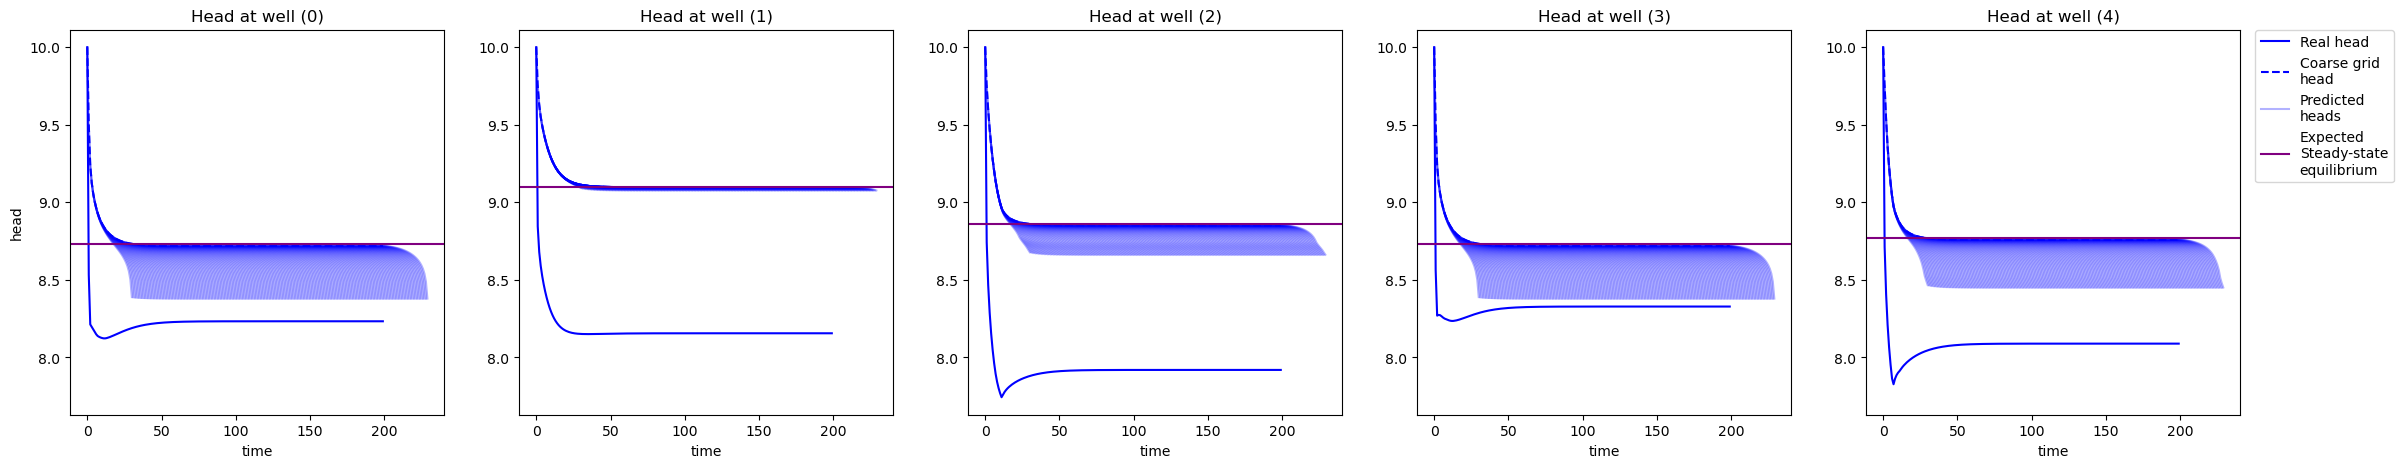

In [124]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data['avg_h_wells'][ii, :], "b--", label="Coarse grid\nhead")
    # Display predicted evolution
    dt = np.linspace(0,30, 31)
    for t0, h_pred in enumerate(np.rollaxis(data['pred_avg_h_wells'], 2)):
        t = t0 + dt
        ax_h.plot(t, h_pred[ii, :], "b-", alpha=0.3,
                    label="Predicted\nheads" if t0==0 else None)
    ax_h.axhline(h_eq[ii], c="purple", label="Expected\nSteady-state\nequilibrium")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

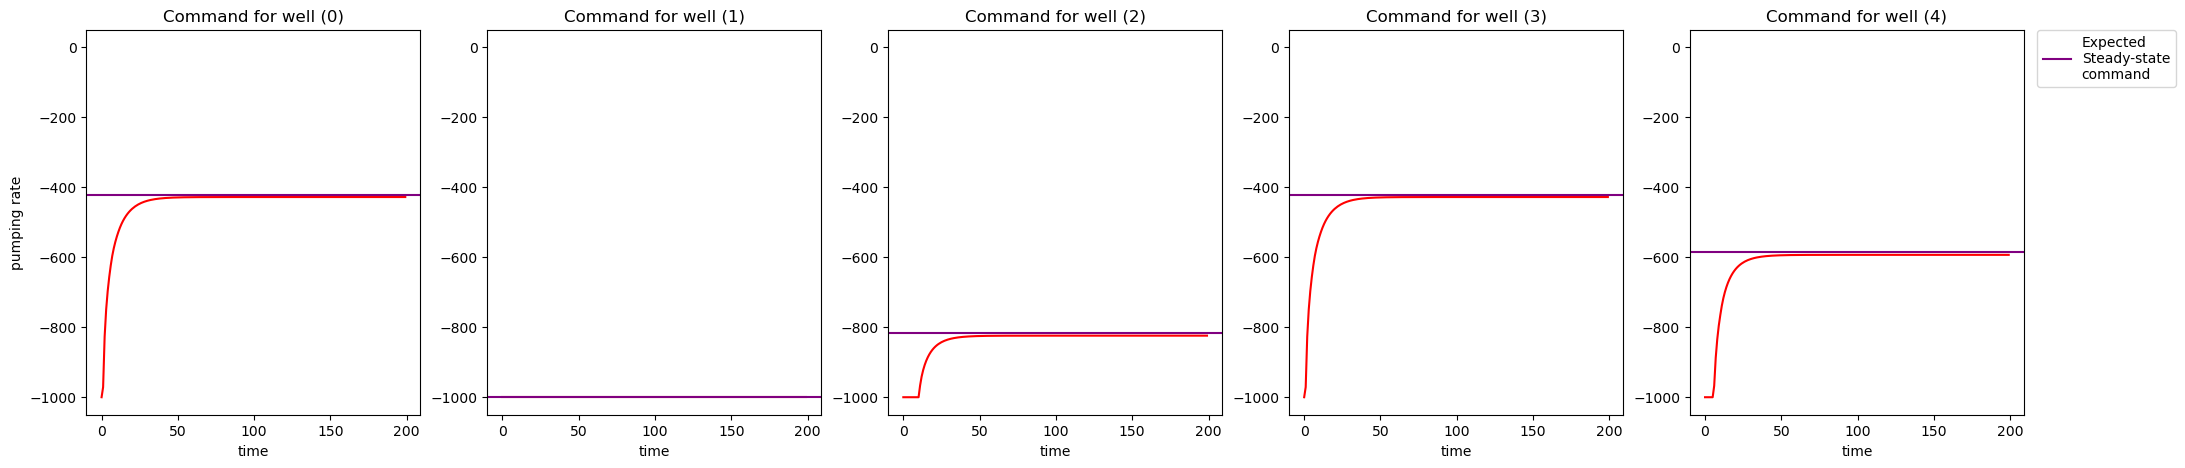

In [72]:
fig_q = plt.figure(figsize=(25,5))
ax_q = None
for ii in range(5):
    ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
    ttl = f"Command for well ({ii})"
    ax_q.set_title(ttl)
    ax_q.set_xlabel("time")
    if ii == 0:
        ax_q.set_ylabel("pumping rate")
    ax_q.plot(data['q_rates'][ii, :], "r-")
    ax_q.axhline(u_eq[ii], c="purple", label="Expected\nSteady-state\ncommand")
    ax_q.set_ylim([-1050, 50])
ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

We indeed observe a Turnpike effect.

## Color test

In [ ]:
from matplotlib.collections import LineCollection

def colored_line_between_pts(x, y, c, ax, **lc_kwargs):
    """
    Plot a line with a color specified between (x, y) points by a third value.

    It does this by creating a collection of line segments between each pair of
    neighboring points. The color of each segment is determined by the
    made up of two straight lines each connecting the current (x, y) point to the
    midpoints of the lines connecting the current point with its two neighbors.
    This creates a smooth line with no gaps between the line segments.

    Parameters
    ----------
    x, y : array-like
        The horizontal and vertical coordinates of the data points.
    c : array-like
        The color values, which should have a size one less than that of x and y.
    ax : Axes
        Axis object on which to plot the colored line.
    **lc_kwargs
        Any additional arguments to pass to matplotlib.collections.LineCollection
        constructor. This should not include the array keyword argument because
        that is set to the color argument. If provided, it will be overridden.

    Returns
    -------
    matplotlib.collections.LineCollection
        The generated line collection representing the colored line.
    """
    if "array" in lc_kwargs:
        plt.warnings.warn('The provided "array" keyword argument will be overridden')

    # Check color array size (LineCollection still works, but values are unused)
    if len(c) != len(x) - 1:
        plt.warnings.warn(
            "The c argument should have a length one less than the length of x and y. "
            "If it has the same length, use the colored_line function instead."
        )

    # Create a set of line segments so that we can color them individually
    # This creates the points as an N x 1 x 2 array so that we can stack points
    # together easily to get the segments. The segments array for line collection
    # needs to be (numlines) x (points per line) x 2 (for x and y)
    points = np.array([x, y]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    lc = LineCollection(segments, **lc_kwargs)

    # Set the values used for colormapping
    lc.set_array(c)

    return ax.add_collection(lc)

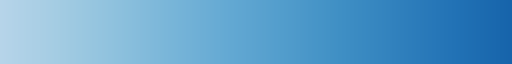

In [ ]:
#plt.get_cmap("Blues")
import matplotlib.colors as colors
cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n="Blues", a=0.3, b=0.8),
        plt.get_cmap("Blues")(np.linspace(0.3, 0.8, 10)))
cmap

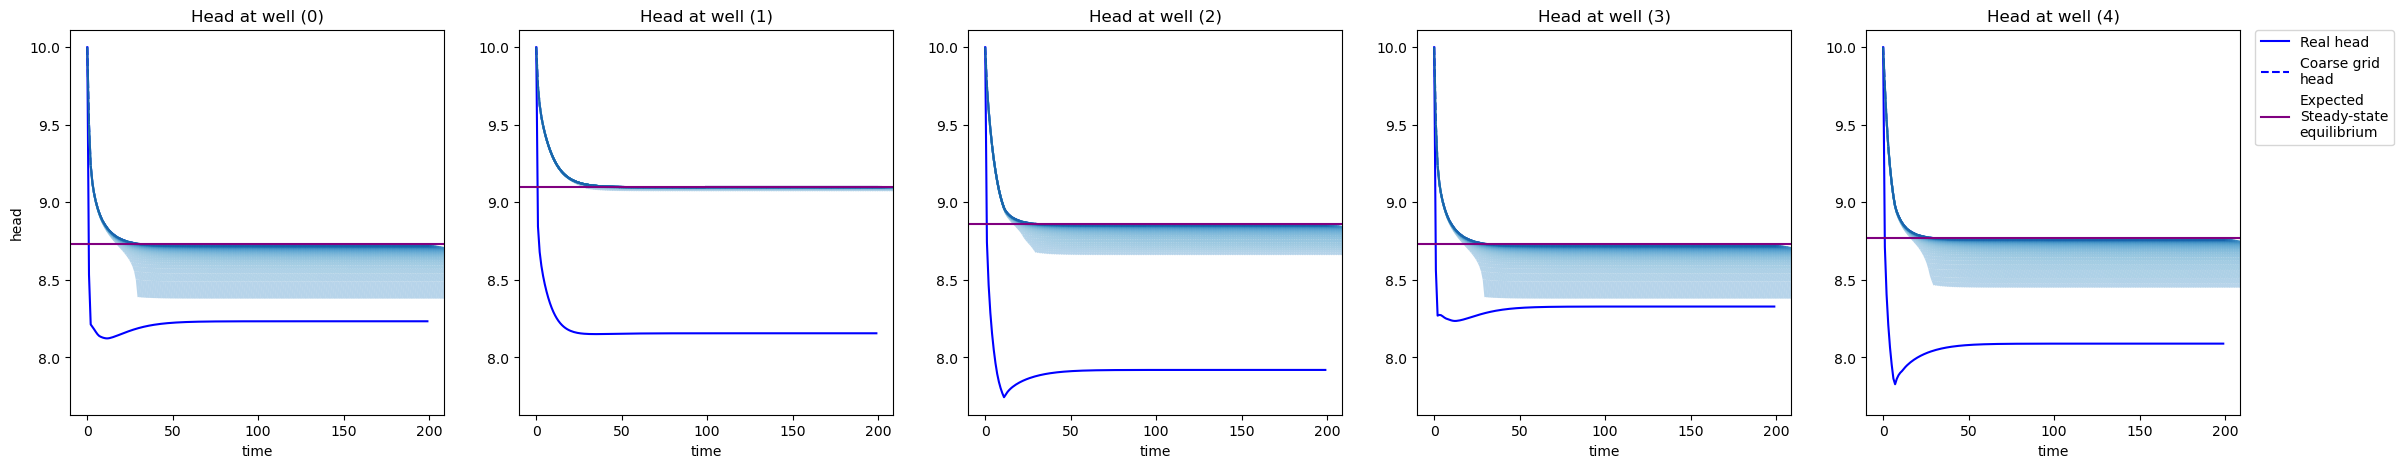

In [ ]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data['avg_h_wells'][ii, :], "b--", label="Coarse grid\nhead")
    # Display predicted evolution
    dt = np.linspace(0,30, 31)
    for t0, h_pred in enumerate(np.rollaxis(data['pred_avg_h_wells'], 2)):
        t = t0 + dt
        colored_line_between_pts(t, h_pred[ii, :], 1/t[1:], ax_h, cmap=cmap)
        # ax_h.plot(t, h_pred[ii, :], "b-", alpha=0.3,
        #             label="Predicted\nheads" if t0==0 else None)
    ax_h.axhline(h_eq[ii], c="purple", label="Expected\nSteady-state\nequilibrium")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)